In [1]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
from openpyxl import load_workbook

# A notebook bárhonnan indítható a workspace-ben: megkeressük a Homework 4 gyökerét.
def find_homework_dir():
    start = Path.cwd().resolve()
    for candidate in (start, *start.parents):
        if candidate.name == "Homework 4" and (candidate / "Sources").is_dir():
            return candidate
        nested = candidate / "Homework 4"
        if (nested / "Sources").is_dir():
            return nested
    raise FileNotFoundError("Nem találom a Homework 4/Sources mappát a jelenlegi könyvtárból.")

HOMEWORK_DIR = find_homework_dir()
SOURCE_FILE = HOMEWORK_DIR / "Sources" / "Kiss_Eszter Anna_I6LX5B_excel file_(Hungary) Ez a divat (top down approach).xlsx"
PROCESS_DIR = HOMEWORK_DIR / "process"
PROCESS_DIR.mkdir(parents=True, exist_ok=True)

assert SOURCE_FILE.exists(), f"Hiányzó forrásfájl: {SOURCE_FILE}"
wb_values = load_workbook(SOURCE_FILE, data_only=True, read_only=True)
wb_formulas = load_workbook(SOURCE_FILE, data_only=False, read_only=True)

records = []
issue_audit = []
invalid_codes = []
summary_formula_rows = {}

for sheet_name in wb_values.sheetnames:
    try:
        year = int(sheet_name)
    except ValueError:
        continue

    ws = wb_values[sheet_name]
    ws_formulas = wb_formulas[sheet_name]
    formula_rows = [
        row_index
        for row_index in range(1, ws.max_row + 1)
        if any(ws_formulas.cell(row_index, col_index).data_type == "f" for col_index in range(2, 6))
    ]
    if not formula_rows:
        raise ValueError(f"A(z) {year} munkalapon nem találtam összesítő képletsort.")

    first_summary_row = min(formula_rows)
    last_raw_row = first_summary_row - 2
    summary_formula_rows[year] = first_summary_row

    for quarter_index, skirt_col in enumerate(range(2, 6), start=1):
        month = str(ws.cell(1, skirt_col).value).strip()
        ad_col = 8 + quarter_index  # I, J, K, L: a négy negyedéves oszlop

        small_cells = [ws.cell(row_index, ad_col).value for row_index in range(1, 7)]
        high_cells = [ws.cell(row_index, ad_col).value for row_index in range(8, 14)]
        unexpected_ad_values = [
            value for value in small_cells + high_cells
            if value is not None and not isinstance(value, (int, float))
        ]
        if unexpected_ad_values:
            raise ValueError(f"Nem numerikus hirdetésszám a(z) {year} Q{quarter_index} negyedévben: {unexpected_ad_values}")

        small_ads = sum(float(value) for value in small_cells if isinstance(value, (int, float)))
        high_ads = sum(float(value) for value in high_cells if isinstance(value, (int, float)))
        issue_id = f"{year}-Q{quarter_index}"
        issue_codes = []

        for row_index in range(4, last_raw_row + 1):
            code = ws.cell(row_index, skirt_col).value
            if code is None:
                continue
            if not isinstance(code, (int, float)) or not float(code).is_integer() or not 1 <= int(code) <= 6:
                invalid_codes.append((year, quarter_index, row_index, code))
                continue

            code = int(code)
            issue_codes.append(code)
            records.append({
                "year": year,
                "quarter": quarter_index,
                "month": month,
                "issue_id": issue_id,
                "source_row": row_index,
                "code_raw": code,
                "target": int(code >= 5),
                "small_ads": small_ads,
                "high_ads": high_ads,
                "small_blank_categories": sum(value is None for value in small_cells),
                "high_blank_categories": sum(value is None for value in high_cells),
            })

        issue_audit.append({
            "year": year,
            "quarter": quarter_index,
            "month": month,
            "issue_id": issue_id,
            "n_skirt_observations": len(issue_codes),
            "small_ads": small_ads,
            "high_ads": high_ads,
            "n_small_blank_cells": sum(value is None for value in small_cells),
            "n_high_blank_cells": sum(value is None for value in high_cells),
        })

for workbook in (wb_values, wb_formulas):
    workbook.close()

raw_df = pd.DataFrame(records).sort_values(["year", "quarter", "source_row"]).reset_index(drop=True)
issue_df = pd.DataFrame(issue_audit).sort_values(["year", "quarter"]).reset_index(drop=True)

if invalid_codes:
    raise ValueError(f"Érvénytelen skirt-kódok; kézi ellenőrzés szükséges: {invalid_codes[:10]}")
if raw_df.empty:
    raise ValueError("A nyers adatokból egyetlen érvényes megfigyelés sem olvasható be.")

print(f"Forrás: {SOURCE_FILE.name}")
print(f"Évfülek: {raw_df['year'].min()}–{raw_df['year'].max()} ({raw_df['year'].nunique()} év)")
print(f"Nyers megfigyelések: {len(raw_df):,}; évi-negyedévi csoportok: {raw_df['issue_id'].nunique()}")
print(f"Hiányos vagy érvénytelen kódcellák: {len(invalid_codes)}")
print("Kódok:", sorted(raw_df["code_raw"].unique()))
raw_df.head()

Forrás: Kiss_Eszter Anna_I6LX5B_excel file_(Hungary) Ez a divat (top down approach).xlsx
Évfülek: 1957–1993 (37 év)
Nyers megfigyelések: 4,924; évi-negyedévi csoportok: 135
Hiányos vagy érvénytelen kódcellák: 0
Kódok: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


,year,quarter,month,issue_id,source_row,code_raw,target,small_ads,high_ads,small_blank_categories,high_blank_categories
0,1957,1,January,1957-Q1,4,5,1,1.0,0.0,5,6
1,1957,1,January,1957-Q1,5,3,0,1.0,0.0,5,6
2,1957,1,January,1957-Q1,6,4,0,1.0,0.0,5,6
3,1957,1,January,1957-Q1,7,4,0,1.0,0.0,5,6
4,1957,1,January,1957-Q1,8,4,0,1.0,0.0,5,6


# Klasszifikáció: a magazinban megjelenő szoknyahossz-kategória

## 1. Kérdés és célváltozó

A kérdés az, hogy az adott lapszám évéből, negyedévéből és hirdetési adataiból előre jelezhető-e, hogy egy szoknyamegfigyelés bokáig (5) vagy földig (6) ér-e. A pozitív osztály a hosszú szoknya (`code_raw >= 5`), a negatív az 1–4-es kód. A `small_ads` és `high_ads` a magazin lapszámonkénti hirdetéseinek darabszáma, nem az áruk vagy a tényleges fogyasztás mértéke. Egy téves pozitív jelzés félreviheti a trendértelmezést; egy kihagyott pozitív miatt nem vesszük észre a hosszú szoknyás trendet. Ezek lehetséges elemzési költségek, nem mért pénzügyi értékek.

## 2–3. EDA, tisztítás és hiányzás

A zárolt, utolsó három évnyi teszthalmazt az EDA előtt választom le; az EDA és minden modellválasztás kizárólag a tanítórészt használja. Az EDA-kód megméri a tanítórész pozitív arányát, és ábrázolja az osztályeloszlást, valamint az éves pozitív arányt. A tanítóévek hirdetési táblázatában talált üres cellákat nulla hirdetésként összegzem; ez lehet valódi nulla, de az adatforrás nem zárja ki a hiányos rögzítést. A hiányzás ezért lehet adatminőségi jel, de mivel sem az eredményből, sem az utólagos címkéből nem származik, önmagában nem célérték-szivárgás. A hiányzó cellák számát auditálom, de nem használom bemenetként, mert a hiányzó cellák üzleti jelentése nem egyértelmű, és a modell így nem tanul rá adatminőség-függő szabályt. Nincs hiányzó vagy érvénytelen célkód a tanítórészben; ilyen esetben a betöltés hibával állna meg, nem dobná el vagy töltené ki csendben a sort. A célkódból és a forrássor pozíciójából képzett mezők nem kerülnek a modellbe.

## 4–6. Split, modellek és mutatók

A legutolsó három megfigyelt év (1991–1993) a zárolt teszthalmaz. Időbeli előrejelzésről van szó, ezért nem véletlen rétegzést használok: a fejlesztési CV bővülő időablakos, és minden modell ugyanazokat a 1973–1984-es, hároméves validációs blokkokat kapja. Az azonos lapszámhoz tartozó sorok együtt maradnak; a seed 2026 a véletlen komponensű modellekhez tartozik. A `quarter` egy-hot kódolású, a logisztikus regresszió numerikus mezői foldon belül skálázódnak. Dummy, logisztikus regresszió, döntési fa, Random Forest, XGBoost és HistGradientBoosting szerepel. A fő rangsorolási mutató az átlagos precízióként számolt PR-AUC; mellette balanced accuracy-t, konfúziós mátrixot és a legmagasabb kockázatú 10% precision/recall értékét mérem. A küszöböt előre rögzített 0,5-re állítom. A nyers pontosságot nem használom fő mutatónak, mert a tanítórész 11,3%-os pozitív aránya mellett a mindenkit negatívnak jelölő modell is félrevezetően jónak tűnhet.

## 7–9. Visszacsatolás, hangolás és teszt

A közös időrendi foldok OOF-jóslatain megvizsgálom a HistGradientBoosting hibáit: 0,5 küszöbnél minden OOF-jóslat negatív lett, ezért a modell 319 pozitívat kihagyott; a rangsor top 10%-a 21,2%-os pozitív arányt ért el a teljes OOF-rész 15,1%-os aránya mellett. Hipotézisem, hogy a két hirdetési összeg különbsége (`high_ads - small_ads`) közvetlenül használható küszöböt adhat a fa-alapú modellnek. Ugyanazokon a négy foldon a különbségjellemző PR-AUC változása a HistGradientBoostingnál +0,008 ± 0,007, az XGBoostnál +0,007 ± 0,013, a logisztikus regressziónál pedig 0,000 ± 0,000. Ez bíztató, de csak négy időblokk alapján nem bizonyít általános javulást; különösen az XGBoostnál a változás kisebb a foldok közti szórásnál.

A fejlesztési CV alapján a különbségjellemzős HistGradientBoosting a legjobb jelölt (PR-AUC 0,174 ± 0,054; a logisztikus regresszió alapmodellje 0,168 ± 0,043). A paraméterkeresés csak az 1984-ig tartó adatok foldjait látja; a 1985–1990-es két ellenőrző blokkon a hangolás −0,001 ± 0,002 páros PR-AUC-változást adott, ezért az egyszerűbb alapbeállítást tartom meg. A 1991–1993-as tesztet csak ezután értékelem: a végső modell PR-AUC-ja 0,237 (95%-os lapszám-klaszter bootstrap CI: [0,164; 0,329]), a logisztikus regresszióé 0,336, a Dummyé 0,190. A végső modell teszt top 10%-os precisionje 27,0%, recallja 14,5%; a 0,5 küszöbön egyetlen pozitívot sem jelez. A CV-ben ígéretesebb modell tehát a teszten nem verte meg a logisztikus regressziót; ezt nem próbálom a teszt alapján utólag javítgatni.


Időrendi split: tanító évek 1957–1990 (4,561 sor); a zárolt tesztévek 1991–1993 (363 sor).
A seed a véletlen komponensű modelleknél 2026; az időrendi vágás determinisztikus.
Pozitív osztály: skirt-kód 5 vagy 6 (bokáig vagy földig érő szoknya); az arányt a tanítórészen mérjük.
Kódjelentés a szakdolgozat alapján: 1=miniszoknya, 2=térd fölött, 3=fedi a térdet, 4=térd alatt, 5=bokáig, 6=földig.
Hirdetések: small_ads = megfizethetőbb luxus hirdetéseinek száma (pl. parfüm, kozmetikum, rúzs, testápoló); high_ads = nagyobb értékű luxus hirdetéseinek száma (pl. táska, óra, ékszer, utazás). Ezek darabszámok, nem árak.
Tanító megfigyelések: 4,561; pozitívak: 517; pozitív arány: 11.3%


,darab,arány
Negatív: kód 1–4,4044,0.886648
Pozitív: bokáig/földig (5–6),517,0.113352


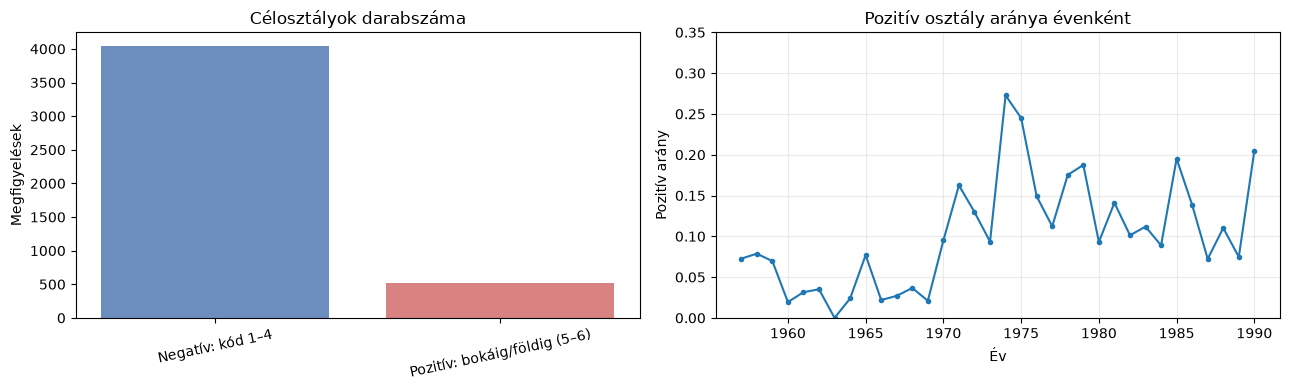

Üres hirdetési kategóriacellák: 1,169/1,632 (71.6%); a modell ezeket a cellaszámokat nem használja.
Hiányzó érték a célban vagy a tervezett alapjellemzőkben: 0
A nyers munkafüzet nem jelöli külön, hogy egy üres hirdetési cella nulla vagy hiányzó rögzítés; ezért a cellaszám csak audit, nem modellbemenet.
Az EDA, a jellemzőválasztás és a modellezés a zárolt teszt címkéit nem használja; a tesztet csak a végső értékelési blokk olvassa ki.

Fejlesztési CV validációs évek: ['1973–1975', '1976–1978', '1979–1981', '1982–1984']



Alapmodellek: a PR-AUC foldonkénti átlagát és szórását mutatjuk; a nyers pontosságot az osztály-aránytalanság miatt nem használjuk fő mutatónak.


,modell,PR-AUC átlag ± fold-szórás,"balanced accuracy @ 0.5, átlag"
1,Logistic regression,0.168 ± 0.043,0.502840
5,HistGradientBoosting,0.166 ± 0.058,0.500000
2,Decision tree,0.164 ± 0.065,0.529644
3,Random forest,0.163 ± 0.062,0.514264
4,XGBoost,0.162 ± 0.062,0.500000
0,Dummy,0.152 ± 0.049,0.500000



Logistic regression: `high_ads - small_ads` páros PR-AUC-változás: +0.000 ± 0.000


,valid_years,PR-AUC_base,PR-AUC_engineered,PR-AUC különbség
0,1973–1975,0.211255,0.211255,0.0
1,1976–1978,0.196744,0.196744,0.0
2,1979–1981,0.141085,0.141085,0.0
3,1982–1984,0.120948,0.120948,0.0


...

Keresés legjobb CV PR-AUC átlaga: 0.175
Keresés során kiválasztott paraméterek: {'model__l2_regularization': 0, 'model__learning_rate': 0.05, 'model__max_iter': 100, 'model__max_leaf_nodes': 15, 'model__min_samples_leaf': 20}


,modell,alap,hangolt,hangolt − alap
fold,valid_years,,,
1,1985–1987,0.172721,0.170275,-0.002446
2,1988–1990,0.125439,0.125439,0.000000


Keresés által nem látott évek páros PR-AUC-változása: -0.001 ± 0.002.
Döntés: az egyszerűbb alapbeállítás marad; a hangolás nem javított az ellenőrző foldokon.

Egyszeri, zárolt tesztértékelés. A küszöb előre rögzített 0.5; a precision@10% a legmagasabb becsült kockázatú tesztsorok pozitív aránya.


,modell,PR-AUC,balanced accuracy,küszöb,"konfúziós mátrix [[TN, FP], [FN, TP]]",precision@10%,recall@10%
0,Végső HistGradientBoosting (különbségjellemző),0.237105,0.500000,0.5,"[[294, 0], [69, 0]]",0.270270,0.144928
1,Alap HistGradientBoosting,0.248111,0.500000,0.5,"[[294, 0], [69, 0]]",0.270270,0.144928
2,Logisztikus regresszió (alapmodell),0.336239,0.561224,0.5,"[[36, 258], [0, 69]]",0.459459,0.246377
3,Dummy,0.190083,0.500000,0.5,"[[294, 0], [69, 0]]",NaN,NaN


Végső modell teszt PR-AUC: 0.237; 95%-os lapszám-klaszter bootstrap CI: [0.164, 0.329] (2000 újramintázás, 12 tesztlapszám).


In [2]:
# EDA, időrendi CV, modellek, feature engineering, hangolás és egyszeri teszt
analysis_code = (HOMEWORK_DIR / 'Solution' / 'model_analysis.py').read_text(encoding='utf-8')
exec(compile(analysis_code, str(HOMEWORK_DIR / 'Solution' / 'model_analysis.py'), 'exec'), globals())

## 10. Korlátok

A hirdetési bemenetek lapszámonként ismétlődnek, a teszt pedig csak 12 lapszámot fed le, ezért a képi megfigyelések nem függetlenek, és a bizonytalanság nagy. A történeti együttjárás nem bizonyítja, hogy a hirdetési mix okozza a szoknyahossz változását, és a modell más magazinokra vagy korszakokra nem feltétlenül általánosítható. A végső modell a teszten nem verte meg a logisztikus regressziót, továbbá 0,5 küszöbnél egyetlen pozitívot sem jelzett, így gyakorlati használathoz új, időben későbbi adatokon végzett validáció kell.